In [56]:
# Importamos las librerias necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score


Ahora preparemos todos los datos para después entrenar nuestros modelos MLP

In [57]:
# Leemos el dataset 
df = pd.read_csv("Classified_Data.csv")
df.head()

,Unnamed: 0,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ,TARGET CLASS
0,0,0.913917,1.162073,0.567946,0.755464,0.780862,0.352608,0.759697,0.643798,0.879422,1.231409,1
1,1,0.635632,1.003722,0.535342,0.825645,0.924109,0.648450,0.675334,1.013546,0.621552,1.492702,0
2,2,0.721360,1.201493,0.921990,0.855595,1.526629,0.720781,1.626351,1.154483,0.957877,1.285597,0
3,3,1.234204,1.386726,0.653046,0.825624,1.142504,0.875128,1.409708,1.380003,1.522692,1.153093,1
4,4,1.279491,0.949750,0.627280,0.668976,1.232537,0.703727,1.115596,0.646691,1.463812,1.419167,1


In [58]:
# Eliminamos la primer columna (indices)
df = df.iloc[:, 1:]
# Visualizamos nuestro df
df.head()

,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ,TARGET CLASS
0,0.913917,1.162073,0.567946,0.755464,0.780862,0.352608,0.759697,0.643798,0.879422,1.231409,1
1,0.635632,1.003722,0.535342,0.825645,0.924109,0.648450,0.675334,1.013546,0.621552,1.492702,0
2,0.721360,1.201493,0.921990,0.855595,1.526629,0.720781,1.626351,1.154483,0.957877,1.285597,0
3,1.234204,1.386726,0.653046,0.825624,1.142504,0.875128,1.409708,1.380003,1.522692,1.153093,1
4,1.279491,0.949750,0.627280,0.668976,1.232537,0.703727,1.115596,0.646691,1.463812,1.419167,1


In [59]:
# Seleccionamos los inputs y el output 
X = df.drop("TARGET CLASS", axis = 1)
y = df["TARGET CLASS"]

In [60]:
# Dividimos nuestros datos en entrenamiento y prueba 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 0)


In [62]:
# Estandarizamos los inputs (restamos la media y dividimos entre su desviación estándar)
scaler = StandardScaler()
X_train_estand = scaler.fit_transform(X_train)
X_test_estand = scaler.transform(X_test)

Entrenaremos 3 modelos con las siguientes características: 

- Método de resolución lbfgs

- Semilla 0
  
- Función de activación logística.

Adicionalmente, el primer modelo tiene dos capas ocultas con 10 nodos cada una, el segundo tiene una capa oculta y 10 nodos y el último tiene una sola capa oculta con un nodo: 

![imagen.png](MLP_imagen.png)

In [63]:
# Definimos el primer modelo que utilizaremos
modelo_1 = MLPClassifier(hidden_layer_sizes = (10, 10), solver = "lbfgs", activation = "logistic", random_state = 0, max_iter = 1000)
modelo_1.fit(X_train_estand, y_train)   # Entrenamos el modelo


,hidden_layer_sizes,"(10, ...)"
,activation,'logistic'
,solver,'lbfgs'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,0


In [64]:
# Ahora obtenemos el accuracy para entrenamiento y prueba 
acc_train = accuracy_score(y_train, modelo_1.predict(X_train_estand))
acc_test = accuracy_score(y_test, modelo_1.predict(X_test_estand))

print(f"El accuracy para este primer modelo en entrenamiento es: {acc_train: .4f} y en prueba es: {acc_test: .4f}")

El accuracy para este primer modelo en entrenamiento es:  1.0000 y en prueba es:  0.9067


In [65]:
# Definimos el segundo modelo que utilizaremos
modelo_2 = MLPClassifier(hidden_layer_sizes=(10,), solver = "lbfgs", activation = "logistic", random_state = 0, max_iter = 1000)
modelo_2.fit(X_train_estand, y_train)   # Entrenamos el modelo


,hidden_layer_sizes,"(10,)"
,activation,'logistic'
,solver,'lbfgs'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,0


In [67]:
# Ahora obtenemos el accuracy para entrenamiento y prueba 
acc_train_2 = accuracy_score(y_train, modelo_2.predict(X_train_estand))
acc_test_2 = accuracy_score(y_test, modelo_2.predict(X_test_estand))

print(f"El accuracy para este segundo modelo en entrenamiento es: {acc_train_2: .4f} y en prueba es: {acc_test_2: .4f}")

El accuracy para este segundo modelo en entrenamiento es:  0.9986 y en prueba es:  0.9033


In [68]:
# Definimos el tercer modelo que utilizaremos
modelo_3 = MLPClassifier(hidden_layer_sizes=(1,), solver = "lbfgs", activation = "logistic", random_state = 0, max_iter = 1000)
modelo_3.fit(X_train_estand, y_train)   # Entrenamos el modelo


,hidden_layer_sizes,"(1,)"
,activation,'logistic'
,solver,'lbfgs'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,0


In [69]:
# Ahora obtenemos el accuracy para entrenamiento y prueba 
acc_train_3 = accuracy_score(y_train, modelo_3.predict(X_train_estand))
acc_test_3 = accuracy_score(y_test, modelo_3.predict(X_test_estand))

print(f"El accuracy para este tercer modelo en entrenamiento es: {acc_train_3: .4f} y en prueba es: {acc_test_3: .4f}")

El accuracy para este tercer modelo en entrenamiento es:  0.9643 y en prueba es:  0.9367


Grafiquemos en un gráfico nuestros resultados

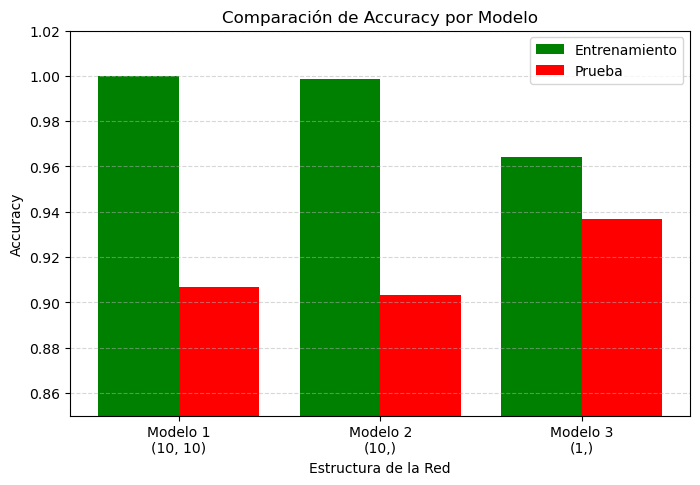

In [70]:
# Definimos los nombres de los modelos y agrupamos las variables de accuracy
modelos = ["Modelo 1\n(10, 10)", "Modelo 2\n(10,)", "Modelo 3\n(1,)"]
lista_acc_train = [acc_train, acc_train_2, acc_train_3]
lista_acc_test = [acc_test, acc_test_2, acc_test_3]

# Definimos la posición de las barras
x = np.arange(len(modelos))
ancho = 0.40

# Creamos la figura
plt.figure(figsize=(8, 5))
plt.bar(x - ancho/2, lista_acc_train, width = ancho, label = "Entrenamiento", color = "green")
plt.bar(x + ancho/2, lista_acc_test, width = ancho, label = "Prueba", color = "red")

# Personalizamos el gráfico
plt.title("Comparación de Accuracy por Modelo", fontsize = 12)
plt.xlabel("Estructura de la Red")
plt.ylabel("Accuracy")
plt.xticks(x, modelos)
plt.ylim(0.85, 1.02)
plt.legend()
plt.grid(axis = "y", linestyle = "--", alpha = 0.5)

plt.show()

Conclusión

Con estos resultados podemos concluir que elegiriamos el modelo 3 por las siguientes razones:

1. Es el modelo mas sencillo, puesto que unicamente tiene una capa oculta y un nodo.
2. A pesar de que fue el que tuvo el accuracy más bajo en entrenamiento, en prueba fue el que tuvo un resultado mayor, dejandonos ver que no memorizó los datos que le dimos (puede que no sufra de overfitting) y para futuras predicciones con datos nuevos funcionará mejor.

